In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
from sklearn.preprocessing import LabelEncoder

In [2]:
dataset = pd.read_excel('Iris_analysis.xlsx', sheet_name=2)
dataset

,sep len,sep wid,pet len,pet wid,class,train/test
0,5.1,3.5,1.4,0.2,Iris-setosa,train
1,4.9,3.0,1.4,0.2,Iris-setosa,test
2,4.7,3.2,1.3,0.2,Iris-setosa,train
3,4.6,3.1,1.5,0.2,Iris-setosa,test
4,5.0,3.6,1.4,0.2,Iris-setosa,train
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica,test
146,6.3,2.5,5.0,1.9,Iris-virginica,train
147,6.5,3.0,5.2,2.0,Iris-virginica,test
148,6.2,3.4,5.4,2.3,Iris-virginica,train


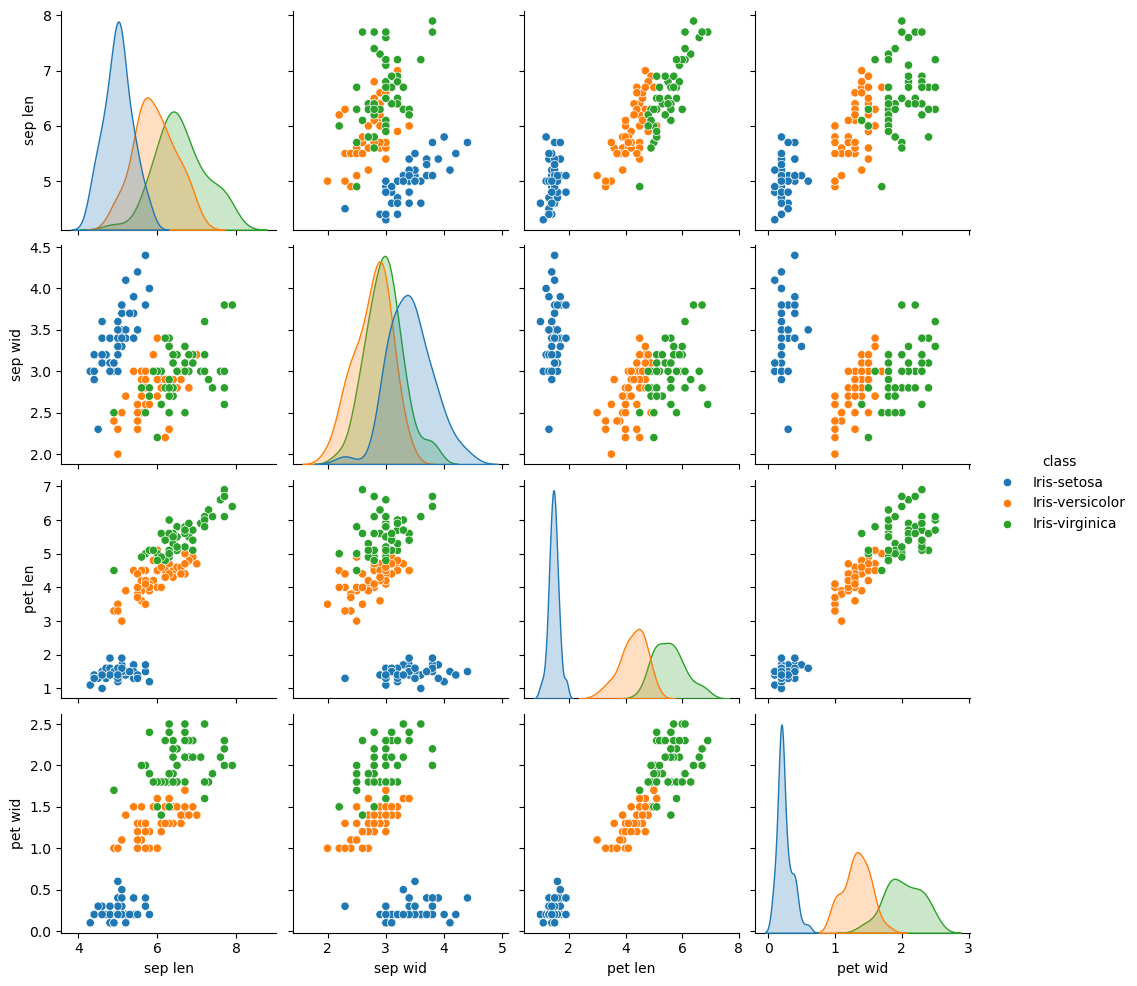

In [3]:
sns.pairplot(dataset, hue='class');
#plt.savefig('./figs/scatters.jpg', format='jpg', bbox_inches="tight", pad_inches=0.01)

In [4]:
train_set = dataset[dataset['train/test'] == 'train'].copy()
test_set = dataset[dataset['train/test'] == 'test'].copy()
test_set.reset_index(drop = True, inplace=True)

In [5]:
class_means = train_set.groupby('class').mean(numeric_only=True)
class_means

,sep len,sep wid,pet len,pet wid
class,,,,
Iris-setosa,5.024,3.480,1.456,0.224
Iris-versicolor,5.992,2.776,4.308,1.352
Iris-virginica,6.504,2.936,5.564,2.076


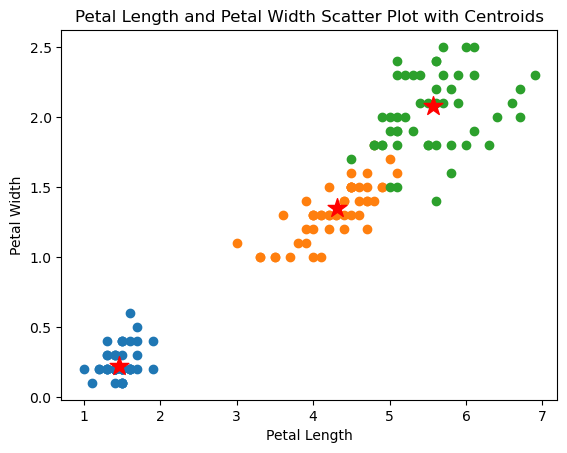

In [6]:
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.title('Petal Length and Petal Width Scatter Plot with Centroids')
plt.scatter(dataset[dataset['class'] == 'Iris-setosa']['pet len'], dataset[dataset['class'] == 'Iris-setosa']['pet wid'])
plt.scatter(dataset[dataset['class'] == 'Iris-versicolor']['pet len'], dataset[dataset['class'] == 'Iris-versicolor']['pet wid'])
plt.scatter(dataset[dataset['class'] == 'Iris-virginica']['pet len'], dataset[dataset['class'] == 'Iris-virginica']['pet wid'])
plt.scatter(class_means['pet len']['Iris-setosa'], class_means['pet wid']['Iris-setosa'], c='red', marker='*', s=200)
plt.scatter(class_means['pet len']['Iris-versicolor'], class_means['pet wid']['Iris-versicolor'], c='red', marker='*', s=200)
plt.scatter(class_means['pet len']['Iris-virginica'], class_means['pet wid']['Iris-virginica'], c='red', marker='*', s=200);

In [7]:
label_encoder = LabelEncoder()
train_set['class'] = label_encoder.fit_transform(train_set['class'])
train_set['class']

0      0
2      0
4      0
6      0
8      0
      ..
140    2
142    2
144    2
146    2
148    2
Name: class, Length: 75, dtype: int32

In [8]:
test_set['class'] = label_encoder.transform(test_set['class'])
test_set['class']

0     0
1     0
2     0
3     0
4     0
     ..
70    2
71    2
72    2
73    2
74    2
Name: class, Length: 75, dtype: int32

In [9]:
class centroid_based_model:
    def __init__(self,):
        pass
        
    def fit(self, X_train, y_train):
        self.class_centroids = {}
        for class_name in np.unique(y_train):
            class_indices = np.where(y_train == class_name)
            centroid = np.mean(X_train[class_indices], axis=0)
            self.class_centroids[class_name] = centroid
        
    
    def predict(self, X_test):
        y_pred = []
        for sample in X_test:
            distances = [np.linalg.norm(sample - centroid) for centroid in self.class_centroids.values()]
            closest_class = list(self.class_centroids.keys())[np.argmin(distances)]
            y_pred.append(closest_class)
        return np.array(y_pred)
    
    def score(self, X_test, y_test):
        if len(y_test) == 0:
            raise ValueError("Test set cannot be empty.")
        return np.mean(self.predict(X_test) == y_test)
    

In [10]:
#with 1 and 3 (pet len and sep len)

X_train = np.array(train_set[['sep len', 'pet len']])
X_test = np.array(test_set[['sep len','pet len']])
y_train = np.array(train_set['class'])
y_test = np.array(test_set['class'])

model = centroid_based_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
model.score(X_test, y_test)

0.8933333333333333

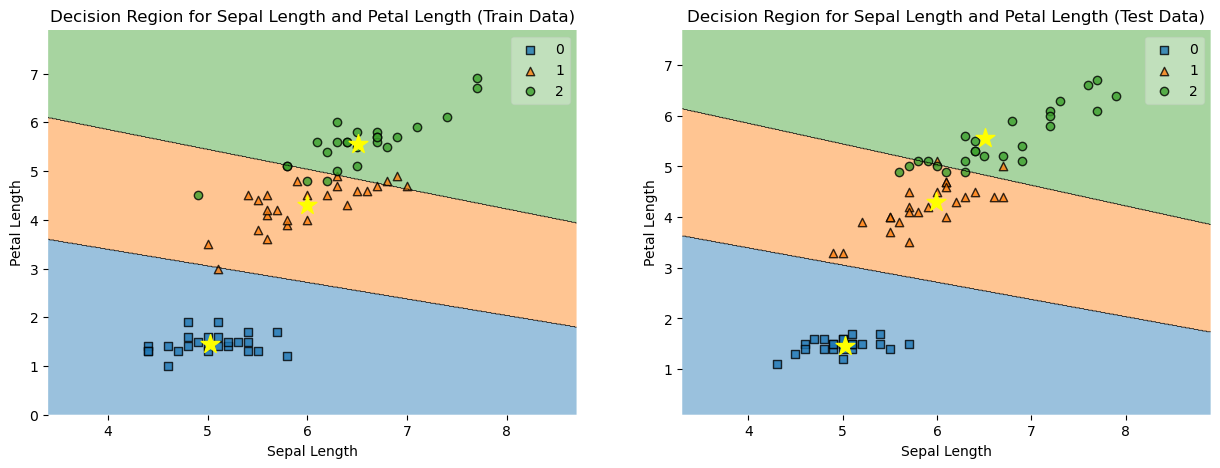

In [11]:
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.title('Decision Region for Sepal Length and Petal Length (Train Data)')
plt.xlabel('Sepal Length')
plt.ylabel('Petal Length')
plot_decision_regions(X_train, y_train, clf=model)
plt.scatter(class_means['sep len']['Iris-setosa'], class_means['pet len']['Iris-setosa'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-versicolor'], class_means['pet len']['Iris-versicolor'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-virginica'], class_means['pet len']['Iris-virginica'], c='yellow', marker='*', s=200)

plt.subplot(1,2,2)
plt.title('Decision Region for Sepal Length and Petal Length (Test Data)')
plt.xlabel('Sepal Length')
plt.ylabel('Petal Length')
plot_decision_regions(X_test, y_test, clf=model)
plt.scatter(class_means['sep len']['Iris-setosa'], class_means['pet len']['Iris-setosa'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-versicolor'], class_means['pet len']['Iris-versicolor'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-virginica'], class_means['pet len']['Iris-virginica'], c='yellow', marker='*', s=200);
#plt.savefig('./figs/1and3.jpg', format='jpg', bbox_inches="tight", pad_inches=0.01)

In [12]:
#all 4 features

X_train = np.array(train_set[['sep len', 'sep wid', 'pet len', 'pet wid']])
X_test = np.array(test_set[['sep len', 'sep wid', 'pet len', 'pet wid']])
y_train = np.array(train_set['class'])
y_test = np.array(test_set['class'])

model = centroid_based_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
model.score(X_test, y_test)

0.9333333333333333

In [13]:
#1 and 2
X_train = np.array(train_set[['sep len', 'sep wid']])
X_test = np.array(test_set[['sep len', 'sep wid']])
y_train = np.array(train_set['class'])
y_test = np.array(test_set['class'])

model = centroid_based_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
model.score(X_test, y_test)

0.8533333333333334

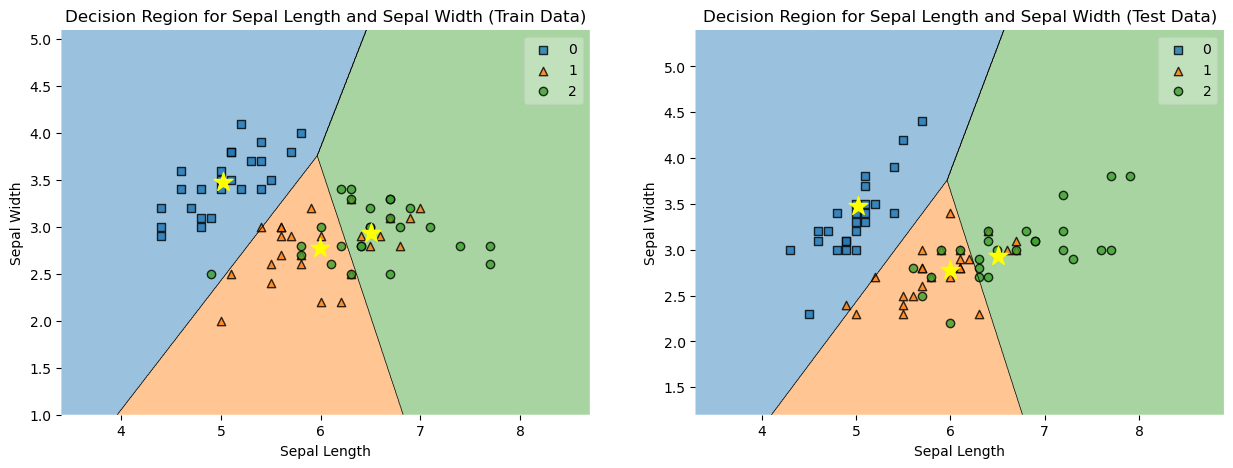

In [14]:
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
plt.title('Decision Region for Sepal Length and Sepal Width (Train Data)')
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plot_decision_regions(X_train, y_train, clf=model)
plt.scatter(class_means['sep len']['Iris-setosa'], class_means['sep wid']['Iris-setosa'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-versicolor'], class_means['sep wid']['Iris-versicolor'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-virginica'], class_means['sep wid']['Iris-virginica'], c='yellow', marker='*', s=200)

plt.subplot(1,2,2)
plt.title('Decision Region for Sepal Length and Sepal Width (Test Data)')
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plot_decision_regions(X_test, y_test, clf=model)
plt.scatter(class_means['sep len']['Iris-setosa'], class_means['sep wid']['Iris-setosa'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-versicolor'], class_means['sep wid']['Iris-versicolor'], c='yellow', marker='*', s=200)
plt.scatter(class_means['sep len']['Iris-virginica'], class_means['sep wid']['Iris-virginica'], c='yellow', marker='*', s=200);
#plt.savefig('./figs/1and2.jpg', format='jpg', bbox_inches="tight", pad_inches=0.01)

In [15]:
#with 3 and 4 (pet len and pet wid)
X_train = np.array(train_set[['pet len', 'pet wid']])
X_test = np.array(test_set[['pet len', 'pet wid']])
y_train = np.array(train_set['class'])
y_test = np.array(test_set['class'])

model = centroid_based_model()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
model.score(X_test, y_test)

0.96

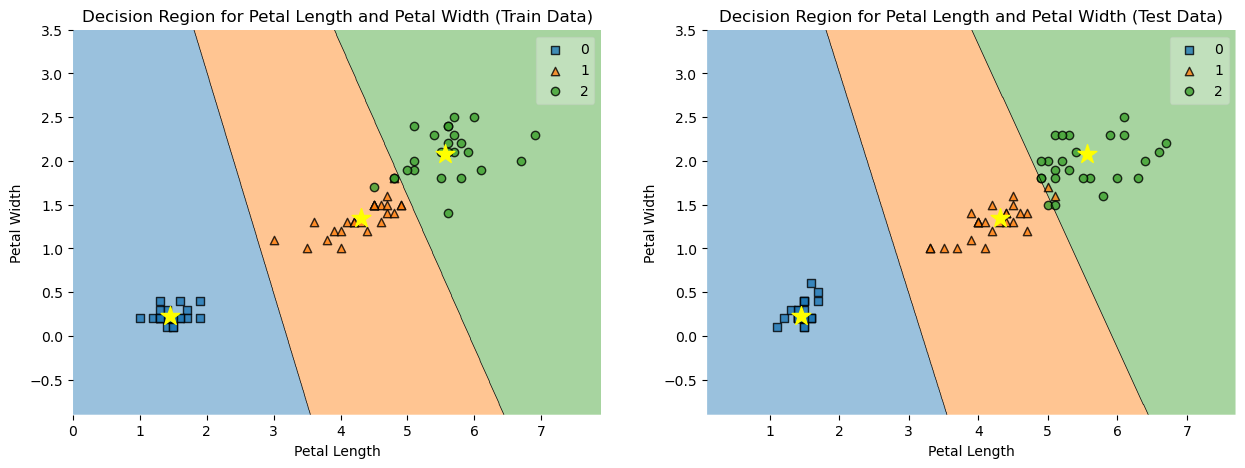

In [16]:
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
plt.title('Decision Region for Petal Length and Petal Width (Train Data)')
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plot_decision_regions(X_train, y_train, clf=model)
plt.scatter(class_means['pet len']['Iris-setosa'], class_means['pet wid']['Iris-setosa'], c='yellow', marker='*', s=200)
plt.scatter(class_means['pet len']['Iris-versicolor'], class_means['pet wid']['Iris-versicolor'], c='yellow', marker='*', s=200)
plt.scatter(class_means['pet len']['Iris-virginica'], class_means['pet wid']['Iris-virginica'], c='yellow', marker='*', s=200)

plt.subplot(1,2,2)
plt.title('Decision Region for Petal Length and Petal Width (Test Data)')
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plot_decision_regions(X_test, y_test, clf=model)
plt.scatter(class_means['pet len']['Iris-setosa'], class_means['pet wid']['Iris-setosa'], c='yellow', marker='*', s=200)
plt.scatter(class_means['pet len']['Iris-versicolor'], class_means['pet wid']['Iris-versicolor'], c='yellow', marker='*', s=200)
plt.scatter(class_means['pet len']['Iris-virginica'], class_means['pet wid']['Iris-virginica'], c='yellow', marker='*', s=200);
#plt.savefig('./figs/3and4.jpg', format='jpg', bbox_inches="tight", pad_inches=0.01)